# Questions

Q1:	Which genres have the highest average popularity?
Q2:	Which genres are the most danceable?
Q3:	Which genres are the most energetic?
Q4:	Does danceability correlate with popularity?
Q5:	Does energy correlate with popularity?
Q6:	What characteristics are associated with highly popular tracks?
Q7:	How do popular and less-popular songs differ?
Q8:	Are explicit songs different from non-explicit songs?
Q9:	Which artists are the most popular?
Q10: Which tracks are the most popular?


PySpark for data loading, aggregation and analysis.

Preserve genre-track associations for genre-level questions.

Use one row per track for track-level comparisons.

Use Pandas and Matplotlib/Seaborn to visualise aggregated results.

Interpret correlations as associations, not evidence of causation.

In [1]:
# Imports

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:

spark = (
    SparkSession.builder
    .appName("Spotify Analytics")
    .master("local[*]")
    .getOrCreate()
)

analytics_path = "../data/processed/spotify_tracks_analytics.csv"
clean_path = "../data/processed/spotify_tracks_clean.csv"

def read_spotify_csv(path):
    return (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .option("quote", '"')
        .option("escape", '"')
        .option("multiLine", True)
        .option("mode", "PERMISSIVE")
        .csv(path)
    )

analytics_df = read_spotify_csv(analytics_path)
clean_df = read_spotify_csv(clean_path)

print("Analytics rows:", analytics_df.count())
print("Unique tracks:", analytics_df.select("track_id").distinct().count())

analytics_df.printSchema()
clean_df.printSchema()


c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Analytics rows: 113549
Unique tracks: 89740
root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- duration_ms: integer (nullable = true)
 |-- explicit: boolean (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- key: integer (nullable = true)
 |-- loudness: double (nullable = true)
 |-- mode: integer (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- time_signature: integer (nullable = true)
 |-- track_genre: string (nullable = true)

root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = tru

In [3]:

clean_df.select(
    "track_id",
    "track_name",
    "artists",
    "popularity",
    "duration_ms",
    "explicit",
    "danceability",
    "energy",
    "track_genre"
).show(10, truncate=False)


+----------------------+---------------------------------------+-------------------------+----------+-----------+--------+------------+------+-----------+
|track_id              |track_name                             |artists                  |popularity|duration_ms|explicit|danceability|energy|track_genre|
+----------------------+---------------------------------------+-------------------------+----------+-----------+--------+------------+------+-----------+
|1fI1TMpz7FVkpoYBhmiywp|get better                             |Eden Elf;Ren Avel        |53        |111734     |false   |0.639       |0.201 |acoustic   |
|6ivkBaxvclVhwZDE2uwldj|Belong                                 |Cary Brothers            |51        |255600     |false   |0.426       |0.399 |acoustic   |
|1i7JnFAxC15AuF1dsosbYM|Pero                                   |Zack Tabudlo             |65        |256648     |false   |0.644       |0.412 |acoustic   |
|0yoJHtKTiv9ixa8UFI6tkY|True                                   |Suy Ga

In [4]:
# track_df has one row per track_id dont want the same track appearing multiple times bc of different genres or something
track_features = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "key",
    "mode",
    "time_signature"
]

track_df = (
    clean_df
    .groupBy("track_id")
    .agg(
        *[
            F.avg(c).alias(c)
            for c in track_features
        ],
        F.first("track_name", ignorenulls=True).alias("track_name"),
        F.first("artists", ignorenulls=True).alias("artists"),
        F.first("explicit", ignorenulls=True).alias("explicit"),
        F.first("album_name", ignorenulls=True).alias("album_name")
    )
)

print("Track-level rows:", track_df.count())
print("Unique track IDs:", track_df.select("track_id").distinct().count())

Track-level rows: 89740
Unique track IDs: 89740


In [5]:
print("=== TRACK_DF ===")
track_df.printSchema()

print("=== ANALYTICS_DF ===")
analytics_df.printSchema()

=== TRACK_DF ===
root
 |-- track_id: string (nullable = true)
 |-- popularity: double (nullable = true)
 |-- duration_ms: double (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- loudness: double (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- key: double (nullable = true)
 |-- mode: double (nullable = true)
 |-- time_signature: double (nullable = true)
 |-- track_name: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- explicit: boolean (nullable = true)
 |-- album_name: string (nullable = true)

=== ANALYTICS_DF ===
root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popu

In [6]:
from pyspark.sql import functions as F

# Columnas que queremos validarn por si acaso, porque tienen unos rangos de valores muy concretos
columnas = {
    "popularity": (0, 100),
    "danceability": (0, 1),
    "energy": (0, 1)
}

# Convertir las columnas a double de forma segura
df_validado = clean_df

for columna in columnas:
    df_validado = df_validado.withColumn(
        columna,
        F.expr(f"try_cast(`{columna}` AS DOUBLE)")
    )

# Comprobar los rangos permitidos
for columna, (minimo, maximo) in columnas.items():
    print(f"\n--- Validación de {columna} ---")

    # Valores fuera de rango
    fuera_rango = df_validado.filter(
        F.col(columna).isNotNull()
        & (
            (F.col(columna) < minimo)
            | (F.col(columna) > maximo)
        )
    )

    # Valores nulos o que no se pudieron convertir
    nulos = df_validado.filter(F.col(columna).isNull())

    print("Valores fuera de rango:", fuera_rango.count())
    print("Valores nulos o no numéricos:", nulos.count())

    # Mostrar ejemplos incorrectos
    fuera_rango.select(columna).show(10, truncate=False)


--- Validación de popularity ---
Valores fuera de rango: 0
Valores nulos o no numéricos: 0
+----------+
|popularity|
+----------+
+----------+


--- Validación de danceability ---
Valores fuera de rango: 0
Valores nulos o no numéricos: 0
+------------+
|danceability|
+------------+
+------------+


--- Validación de energy ---
Valores fuera de rango: 0
Valores nulos o no numéricos: 0
+------+
|energy|
+------+
+------+



In [7]:

from pyspark.sql import functions as F

# ver Valores nulos por columna
null_counts = analytics_df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in analytics_df.columns
])

null_counts.show(truncate=False)

# ver nº registros y canciones únicas
print("Total de registros:", analytics_df.count())
print("Canciones únicas:", analytics_df.select("track_id").distinct().count())

# ver número de géneros musicales
print("Géneros únicos:", analytics_df.select("track_genre").distinct().count())


+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-----+--------------+-----------+
|track_id|artists|album_name|track_name|popularity|duration_ms|explicit|danceability|energy|key|loudness|mode|speechiness|acousticness|instrumentalness|liveness|valence|tempo|time_signature|track_genre|
+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-----+--------------+-----------+
|0       |0      |0         |0         |0         |0          |0       |0           |0     |0  |0       |0   |0          |0           |0               |0       |0      |0    |0             |0          |
+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-----+-------------

In [8]:
from pyspark.sql import functions as F

numeric_columns = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "key",
    "mode",
    "time_signature"
]

for column in numeric_columns:
    try:
        track_df.select(F.avg(F.col(column))).collect()
        print(f"OK: {column}")
    except Exception as e:
        print(f"ERROR en {column}: {str(e)[:300]}")

OK: popularity
OK: duration_ms
OK: danceability
OK: energy
OK: loudness
OK: speechiness
OK: acousticness
OK: instrumentalness
OK: liveness
OK: valence
OK: tempo
OK: key
OK: mode
OK: time_signature


In [9]:
print("Columnas de clean_df:")
clean_df.printSchema()

print("Columnas de analytics_df:")
analytics_df.printSchema()

print("Columnas de track_df:")
print(track_df.columns)

Columnas de clean_df:
root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- duration_ms: integer (nullable = true)
 |-- explicit: boolean (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- key: integer (nullable = true)
 |-- loudness: double (nullable = true)
 |-- mode: integer (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- time_signature: integer (nullable = true)
 |-- track_genre: string (nullable = true)

Columnas de analytics_df:
root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable =

In [10]:
print("=== ANALYTICS DF ===")

analytics_df.select(
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "tempo"
).describe().show()

=== ANALYTICS DF ===
+-------+------------------+------------------+-------------------+-------------------+------------------+
|summary|        popularity|       duration_ms|       danceability|             energy|             tempo|
+-------+------------------+------------------+-------------------+-------------------+------------------+
|  count|            113549|            113549|             113549|             113549|            113549|
|   mean| 33.32443262380118|228081.37084430511| 0.5670312966208237| 0.6420908612775128|122.17574470052679|
| stddev|22.283854778038876|106413.09852473768|0.17340910471619161|0.25105328237724184|29.972954313927886|
|    min|                 0|              8586|                0.0|                0.0|               0.0|
|    max|               100|           5237295|              0.985|                1.0|           243.372|
+-------+------------------+------------------+-------------------+-------------------+------------------+



In [11]:
# overview 
print("Number of tracks:", track_df.count())
print("Number of genre-track associations:", analytics_df.count())
print("Number of genres:", analytics_df.select("track_genre").distinct().count())

track_df.select(
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "tempo"
).describe().show()

Number of tracks: 89740
Number of genre-track associations: 113549
Number of genres: 114
+-------+-----------------+------------------+------------------+-------------------+------------------+
|summary|       popularity|       duration_ms|      danceability|             energy|             tempo|
+-------+-----------------+------------------+------------------+-------------------+------------------+
|  count|            89740|             89740|             89740|              89740|             89740|
|   mean|33.19990315939168|229144.36557833743|0.5621663550256303| 0.6344584717695555|122.05813423222627|
| stddev|20.57525782781841|112945.78033648539|  0.17669202472897|0.25660637855864427|30.117650515714402|
|    min|              0.0|            8586.0|               0.0|                0.0|               0.0|
|    max|            100.0|         5237295.0|             0.985|                1.0|           243.372|
+-------+-----------------+------------------+------------------+------

##  Q1 - Which genres have the highest average popularity?

In [12]:

# Contar cuántas veces aparece cada canción dentro de cada génerom para saber si algunas canciones estan duplicadas/triplicadas/...
duplicate_tracks = (
    analytics_df
    .groupBy("track_genre", "track_id")
    .agg(
        F.count("*").alias("num_apariciones"),
        F.first("track_name").alias("track_name"),
        F.first("artists").alias("artists")
    )
    .filter(F.col("num_apariciones") > 1)
    .orderBy(
        F.desc("num_apariciones"),
        "track_genre"
    )
)

print("Canciones repetidas dentro del mismo género:")
duplicate_tracks.show(50, truncate=False)


Canciones repetidas dentro del mismo género:
+-----------+--------+---------------+----------+-------+
|track_genre|track_id|num_apariciones|track_name|artists|
+-----------+--------+---------------+----------+-------+
+-----------+--------+---------------+----------+-------+



In [13]:
# av popularity by genre
genre_popularity = (
    analytics_df
    .groupBy("track_genre")
    .agg(
        F.avg("popularity").alias("average_popularity"),
        F.count("*").alias("track_count")
    )
    .orderBy(F.desc("average_popularity"))
)

genre_popularity.show(20, truncate=False)

+-----------------+------------------+-----------+
|track_genre      |average_popularity|track_count|
+-----------------+------------------+-----------+
|pop-film         |59.28028028028028 |999        |
|k-pop            |56.963927855711425|998        |
|chill            |53.7047047047047  |999        |
|sad              |52.379            |1000       |
|grunge           |49.58258258258258 |999        |
|indian           |49.528528528528525|999        |
|anime            |48.766766766766764|999        |
|emo              |48.128            |1000       |
|pop              |47.903323262839876|993        |
|sertanejo        |47.866            |1000       |
|progressive-house|46.66166166166166 |999        |
|piano            |45.27755511022044 |998        |
|mandopop         |45.025            |1000       |
|deep-house       |44.78857715430862 |998        |
|brazil           |44.668336673346694|998        |
|electronic       |44.325            |1000       |
|pagode           |44.298      

c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


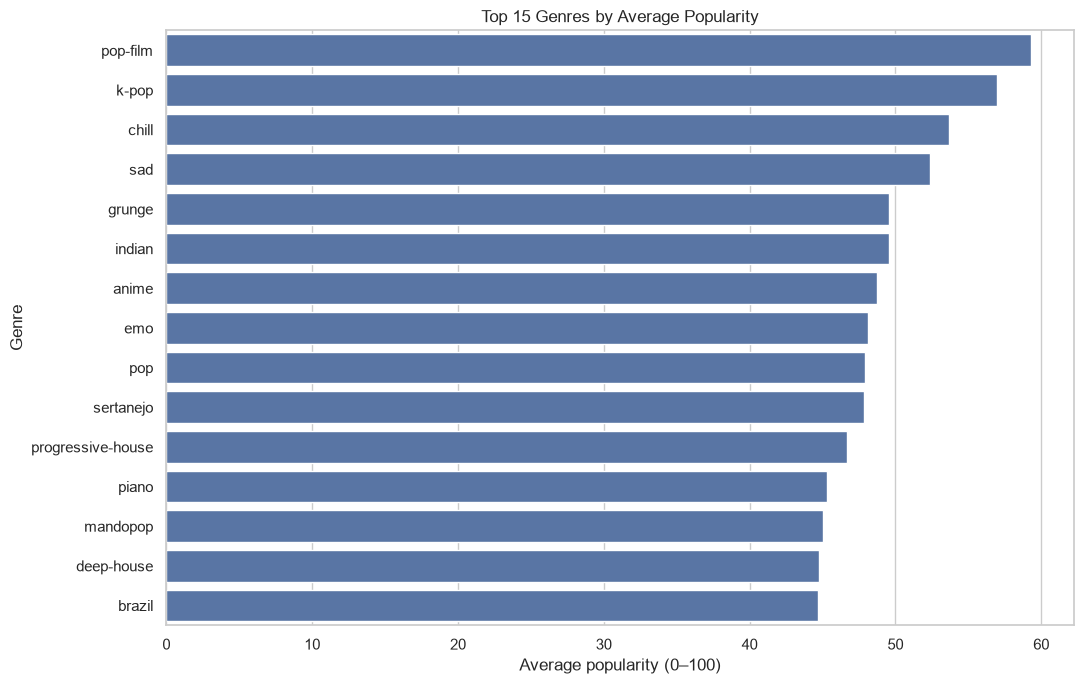

In [14]:
# top 15 generes by av. popularity
genre_popularity_pd = genre_popularity.limit(15).toPandas()

plt.figure(figsize=(11, 7))
sns.barplot(
    data=genre_popularity_pd,
    x="average_popularity",
    y="track_genre"
)
plt.title("Top 15 Genres by Average Popularity")
plt.xlabel("Average popularity (0–100)")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

## Q2 - Which genres are the most danceable?

In [15]:
# av dancaeability by genre
genre_danceability = (
    analytics_df
    .groupBy("track_genre")
    .agg(
        F.avg("danceability").alias("average_danceability"),
        F.count("*").alias("track_count")
    )
    .orderBy(F.desc("average_danceability"))
)

genre_danceability.show(15, truncate=False)

+--------------+--------------------+-----------+
|track_genre   |average_danceability|track_count|
+--------------+--------------------+-----------+
|kids          |0.7786296670030279  |991        |
|chicago-house |0.7662404809619238  |998        |
|reggaeton     |0.758521            |1000       |
|latino        |0.7573957703927494  |993        |
|reggae        |0.7453309999999991  |1000       |
|hip-hop       |0.7359374369323907  |991        |
|dancehall     |0.7340820820820824  |999        |
|minimal-techno|0.7293156312625239  |998        |
|detroit-techno|0.7224659318637267  |998        |
|latin         |0.7214101010101001  |990        |
|children      |0.7164759519038069  |998        |
|deep-house    |0.7105180360721443  |998        |
|sad           |0.6923779999999985  |1000       |
|dance         |0.6876549222797921  |965        |
|study         |0.6852515030060122  |998        |
+--------------+--------------------+-----------+
only showing top 15 rows


c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


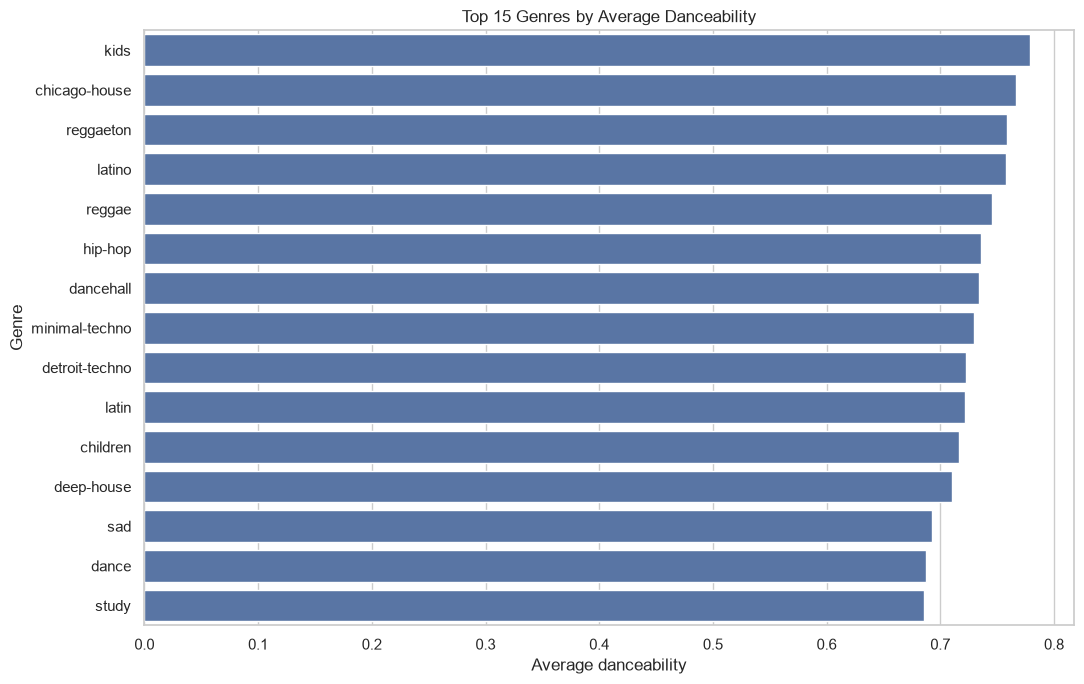

In [16]:
# most danceable genres
danceability_pd = genre_danceability.limit(15).toPandas()

plt.figure(figsize=(11, 7))
sns.barplot(
    data=danceability_pd,
    x="average_danceability",
    y="track_genre"
)
plt.title("Top 15 Genres by Average Danceability")
plt.xlabel("Average danceability")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

## Q3 - Which genres are the most energetic?

In [17]:
# av energy by genre
genre_energy = (
    analytics_df
    .groupBy("track_genre")
    .agg(
        F.avg("energy").alias("average_energy"),
        F.count("*").alias("track_count")
    )
    .orderBy(F.desc("average_energy"))
)

genre_energy.show(15, truncate=False)

+-------------+------------------+-----------+
|track_genre  |average_energy    |track_count|
+-------------+------------------+-----------+
|death-metal  |0.9314684684684688|999        |
|grindcore    |0.9243226452905823|998        |
|metalcore    |0.9144849999999991|1000       |
|happy        |0.9109009009009014|999        |
|hardstyle    |0.9011733466933881|998        |
|drum-and-bass|0.8763795180722902|996        |
|black-metal  |0.8747214643931792|997        |
|heavy-metal  |0.8741523046092188|998        |
|party        |0.8713490945674048|994        |
|j-idol       |0.8685928928928937|999        |
|industrial   |0.8617453000000008|1000       |
|breakbeat    |0.8534964964964966|999        |
|trance       |0.8453863863863864|999        |
|hardcore     |0.842329329329329 |999        |
|metal        |0.8405020040080158|998        |
+-------------+------------------+-----------+
only showing top 15 rows


c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


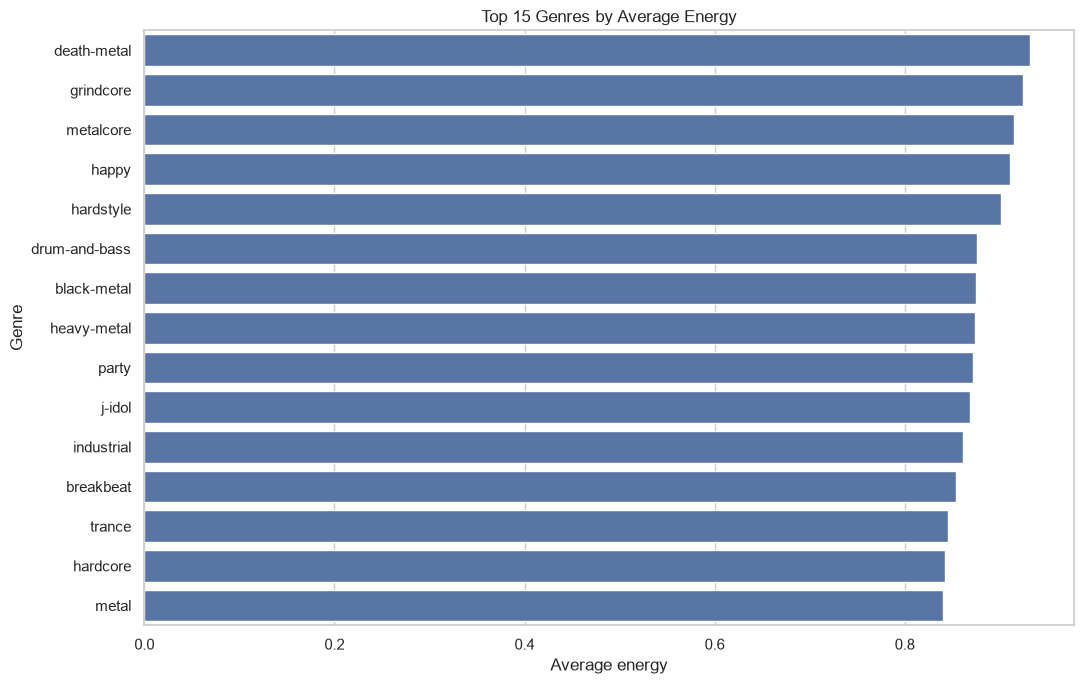

In [18]:
# generes listed by average energy
energy_pd = genre_energy.limit(15).toPandas()

plt.figure(figsize=(11, 7))
sns.barplot(
    data=energy_pd,
    x="average_energy",
    y="track_genre"
)
plt.title("Top 15 Genres by Average Energy")
plt.xlabel("Average energy")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

## Q4 - Does danceability correlate with popularity?

In [19]:
# plot correlation between danceability and popularity. 
# pearson coorrelation coefficient ranges from -1 to 1:
#       1 means perfect positive correlation 
#       -1 means perfect negative correlation,
#       0 means no correlation.
danceability_correlation = track_df.stat.corr(
    "danceability",
    "popularity"
)

print(
    "Correlation between danceability and popularity:",
    round(danceability_correlation, 4)
)

Correlation between danceability and popularity: 0.0643


c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


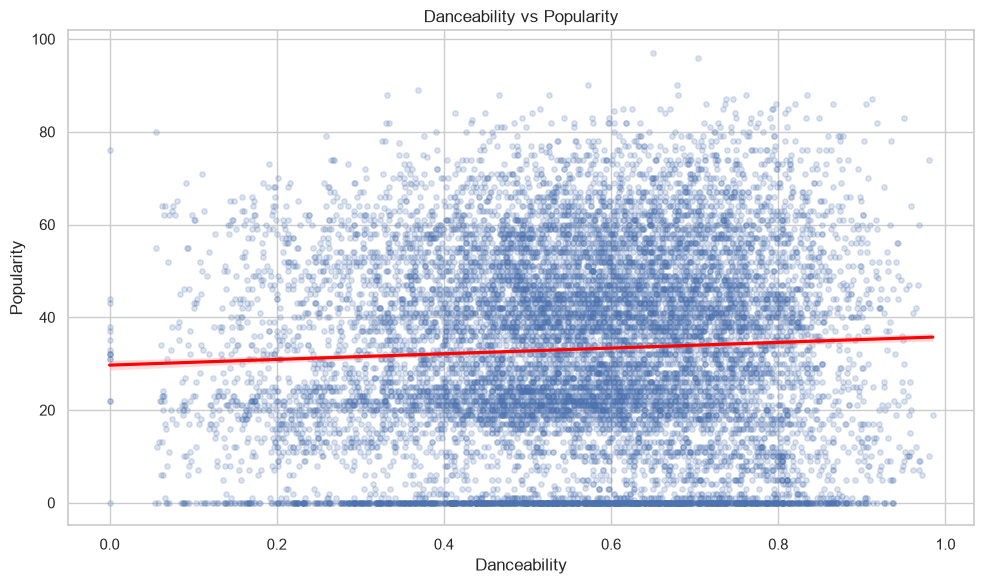

In [20]:
# scatter plot of danceability vs popularity with regression line
danceability_pd = (
    track_df
    .select("danceability", "popularity")
    .dropna()
    .sample(False, 0.15, seed=42)
    .toPandas()
)

plt.figure(figsize=(10, 6))
sns.regplot(
    data=danceability_pd,
    x="danceability",
    y="popularity",
    scatter_kws={"alpha": 0.2, "s": 15},
    line_kws={"color": "red"}
)
plt.title("Danceability vs Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity")
plt.tight_layout()
plt.show()

## Q5 - Does energy correlate with popularity?

In [21]:
# coorelation between energy and popularity
energy_correlation = track_df.stat.corr(
    "energy",
    "popularity"
)

print(
    "Correlation between energy and popularity:",
    round(energy_correlation, 4)
)

Correlation between energy and popularity: 0.0137


c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


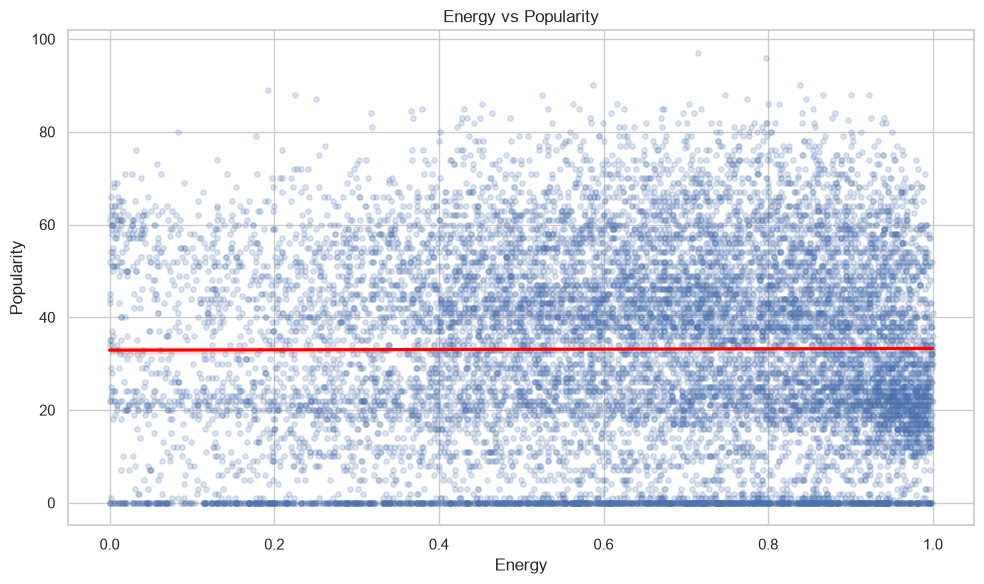

In [22]:
# scatter plot of energy vs popularity with regression line
energy_pd = (
    track_df
    .select("energy", "popularity")
    .dropna()
    .sample(False, 0.15, seed=42)
    .toPandas()
)

plt.figure(figsize=(10, 6))
sns.regplot(
    data=energy_pd,
    x="energy",
    y="popularity",
    scatter_kws={"alpha": 0.2, "s": 15},
    line_kws={"color": "red"}
)
plt.title("Energy vs Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity")
plt.tight_layout()
plt.show()

In [23]:
# compare coorelations (Danceability vs Energy)
correlation_comparison = pd.DataFrame({
    "Feature": ["Danceability", "Energy"],
    "Correlation with popularity": [
        danceability_correlation,
        energy_correlation
    ]
})

display(correlation_comparison)

,Feature,Correlation with popularity
0,Danceability,0.064278
1,Energy,0.013694


## Q6 - What characteristics are associated with highly popular tracks?

In [24]:
# popularity 80th percentile threshold
popularity_threshold = track_df.approxQuantile(
    "popularity",
    [0.80],
    0.001
)[0]

print("80th percentile threshold:", popularity_threshold)

track_df = track_df.withColumn(
    "popularity_group",
    F.when(
        F.col("popularity") >= popularity_threshold,
        "Highly popular"
    ).otherwise("Other tracks")
)

track_df.groupBy("popularity_group").count().show()

80th percentile threshold: 52.0
+----------------+-----+
|popularity_group|count|
+----------------+-----+
|  Highly popular|18758|
|    Other tracks|70982|
+----------------+-----+



In [25]:
# comparison of average audio features between highly popular tracks and other tracks
comparison_features = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "loudness",
    "tempo",
    "duration_ms"
]

feature_comparison = (
    track_df
    .groupBy("popularity_group")
    .agg(
        *[
            F.avg(c).alias(c)
            for c in comparison_features
        ],
        F.count("*").alias("track_count")
    )
)

feature_comparison.show(truncate=False)

+----------------+------------------+------------------+-------------------+------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+-----------+
|popularity_group|danceability      |energy            |speechiness        |acousticness      |instrumentalness   |liveness           |valence            |loudness          |tempo             |duration_ms       |track_count|
+----------------+------------------+------------------+-------------------+------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+-----------+
|Highly popular  |0.5824209510608805|0.6239761629331488|0.07768635248960447|0.3034473636912251|0.1134972400218574 |0.18423548352702868|0.45871048032839334|-8.175992909691864|121.1290150335857 |218881.72177204394|18758      |
|Other tracks    |0.5568137908202079|0.6372285705150598|0.09002048970161439|0.3348486594385899|0.189

c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


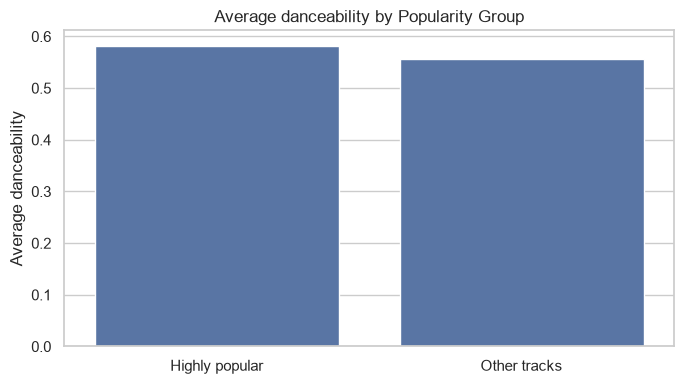

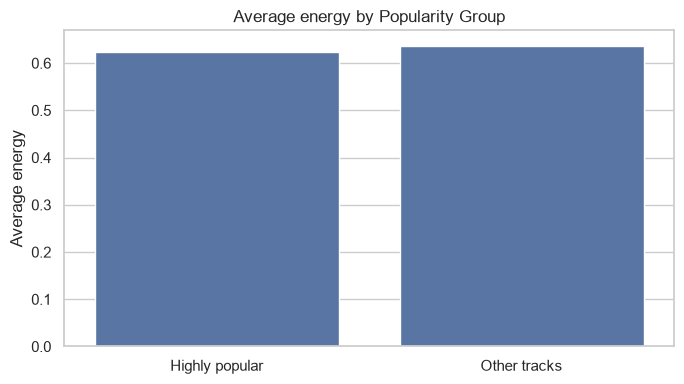

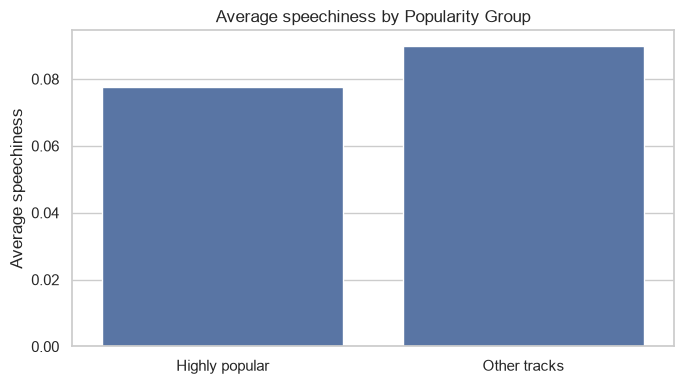

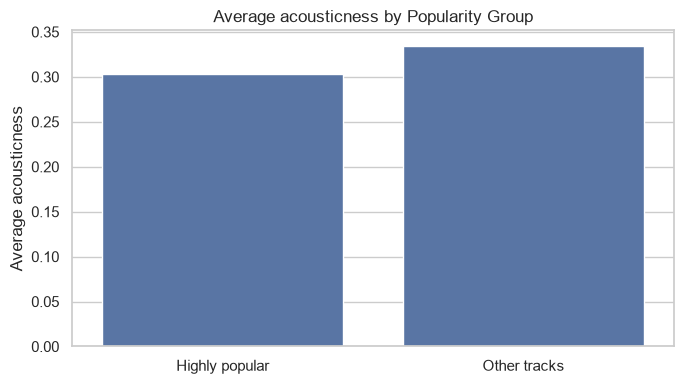

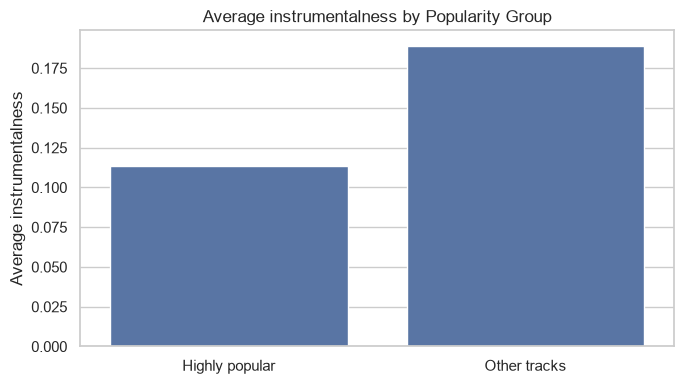

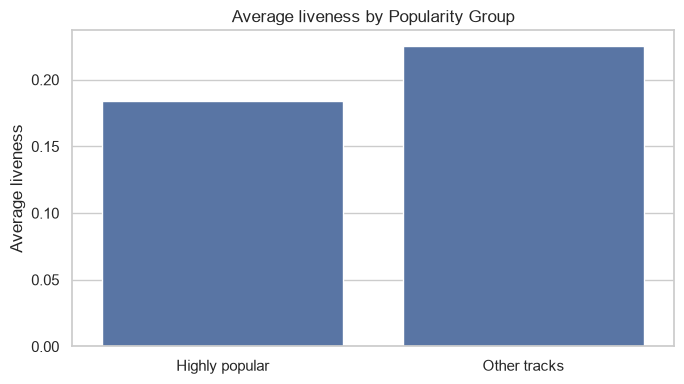

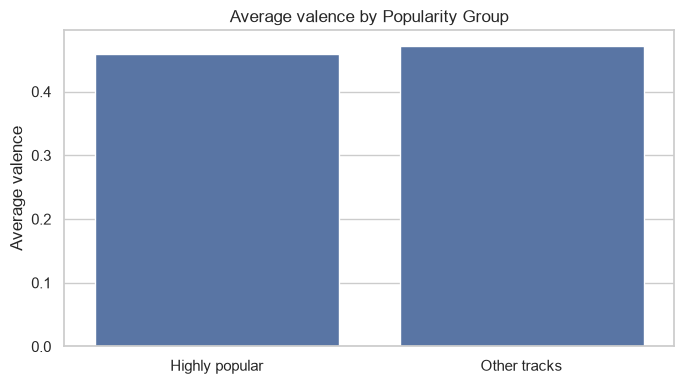

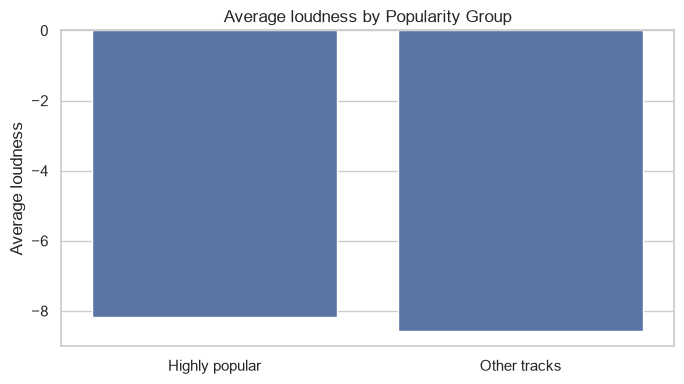

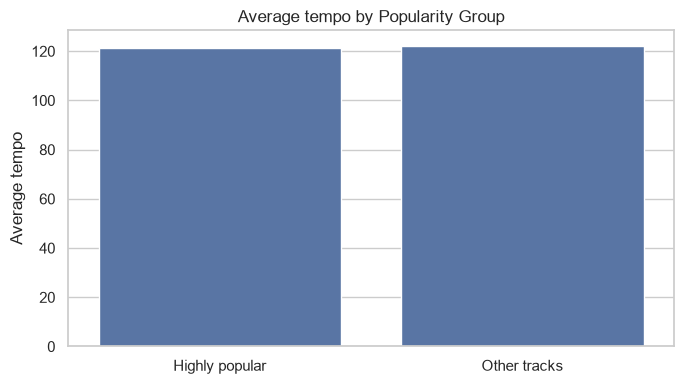

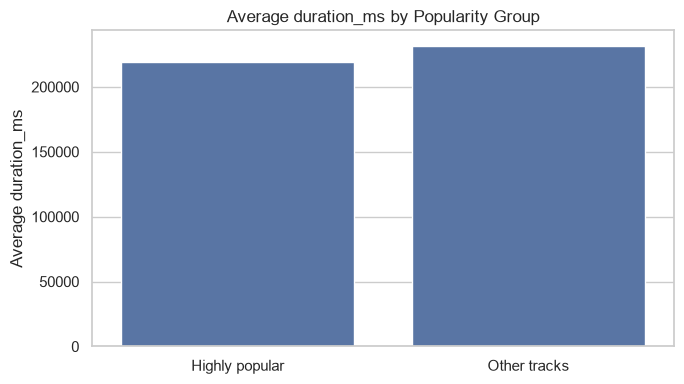

In [26]:
# differences representation
feature_comparison_pd = feature_comparison.toPandas()

feature_comparison_long = feature_comparison_pd.melt(
    id_vars=["popularity_group", "track_count"],
    value_vars=comparison_features,
    var_name="feature",
    value_name="average_value"
)

# Separate plots avoid comparing features on incompatible scales.
for feature in comparison_features:
    plot_data = feature_comparison_long[
        feature_comparison_long["feature"] == feature
    ]

    plt.figure(figsize=(7, 4))
    sns.barplot(
        data=plot_data,
        x="popularity_group",
        y="average_value"
    )
    plt.title(f"Average {feature} by Popularity Group")
    plt.xlabel("")
    plt.ylabel(f"Average {feature}")
    plt.tight_layout()
    plt.show()

## Q7 - How do popular and less-popular songs differ?

In [27]:
# creation of top and bottom groups
lower_threshold, upper_threshold = track_df.approxQuantile(
    "popularity",
    [0.20, 0.80],
    0.001
)

print("20th percentile:", lower_threshold)
print("80th percentile:", upper_threshold)

extreme_groups_df = (
    track_df
    .withColumn(
        "popularity_group",
        F.when(
            F.col("popularity") <= lower_threshold,
            "Bottom 20%"
        ).when(
            F.col("popularity") >= upper_threshold,
            "Top 20%"
        )
    )
    .filter(F.col("popularity_group").isNotNull())
)

extreme_groups_df.groupBy("popularity_group").count().show()

20th percentile: 16.0
80th percentile: 52.0
+----------------+-----+
|popularity_group|count|
+----------------+-----+
|      Bottom 20%|18904|
|         Top 20%|18758|
+----------------+-----+



In [28]:
# compare grouos
extreme_comparison = (
    extreme_groups_df
    .groupBy("popularity_group")
    .agg(
        *[
            F.avg(c).alias(c)
            for c in comparison_features
        ],
        F.avg("popularity").alias("average_popularity"),
        F.count("*").alias("track_count")
    )
)

extreme_comparison.show(truncate=False)

+----------------+------------------+------------------+-------------------+------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+------------------+-----------+
|popularity_group|danceability      |energy            |speechiness        |acousticness      |instrumentalness   |liveness           |valence            |loudness          |tempo             |duration_ms       |average_popularity|track_count|
+----------------+------------------+------------------+-------------------+------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+------------------+-----------+
|Bottom 20%      |0.570287314853999 |0.6108849247037671|0.0808970641134152 |0.3304651818831994|0.24396570931495962|0.18881332522217528|0.47318885262378324|-9.119526713922973|120.52481019889971|230060.10579771476|4.55098228140177  |18904      |
|Top 20%         |0.5824

c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


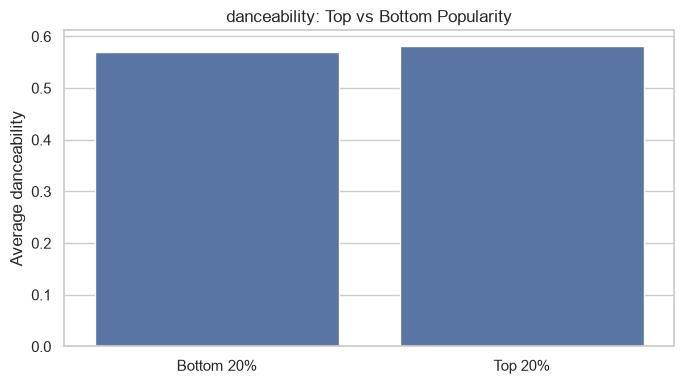

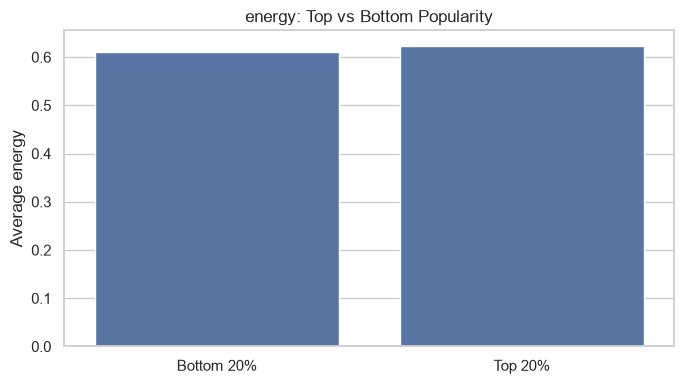

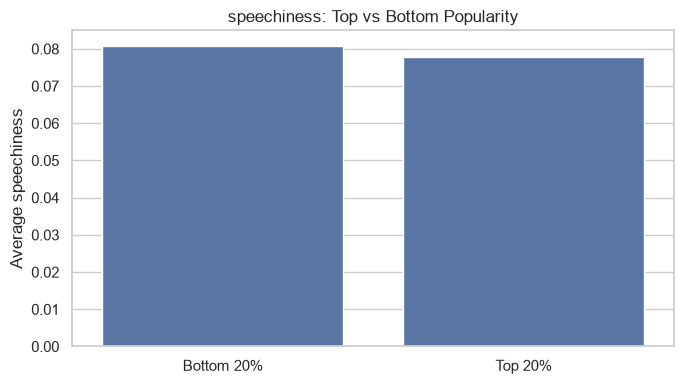

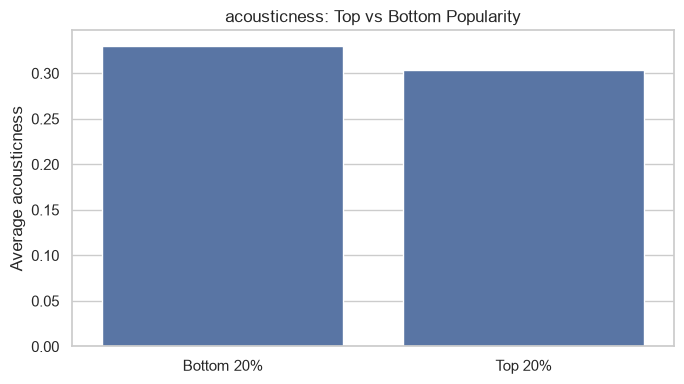

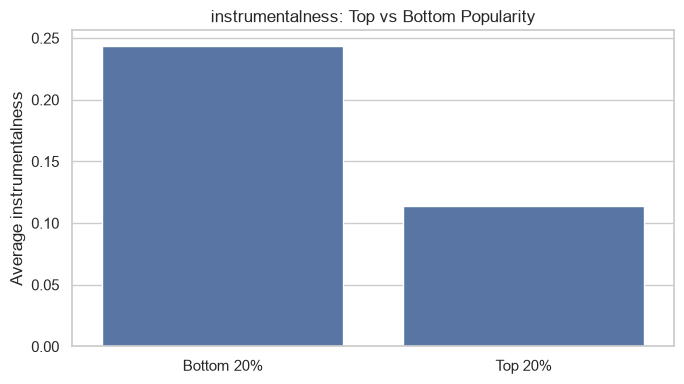

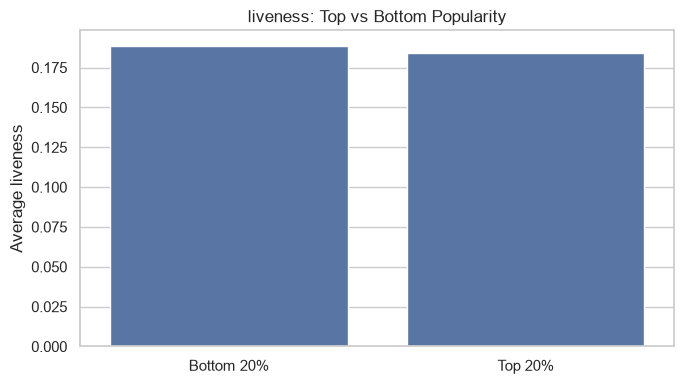

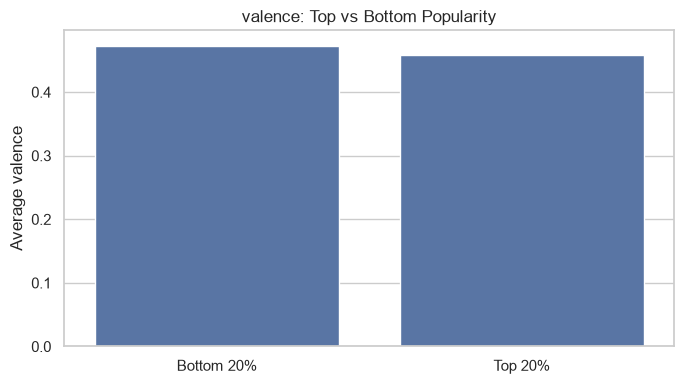

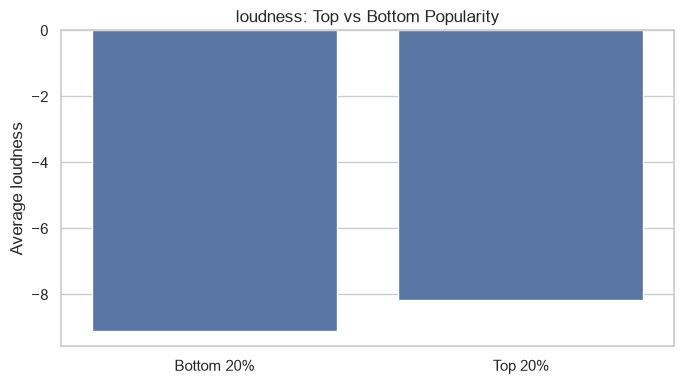

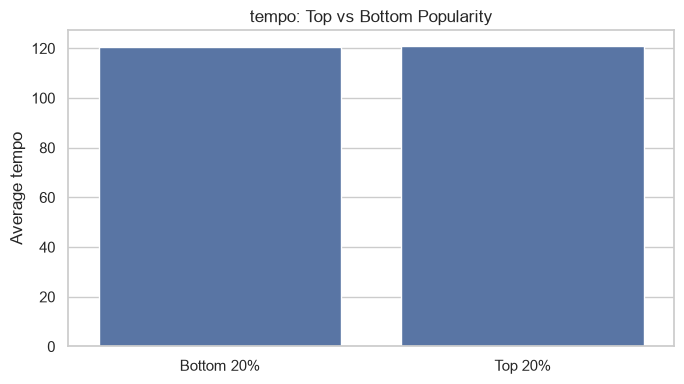

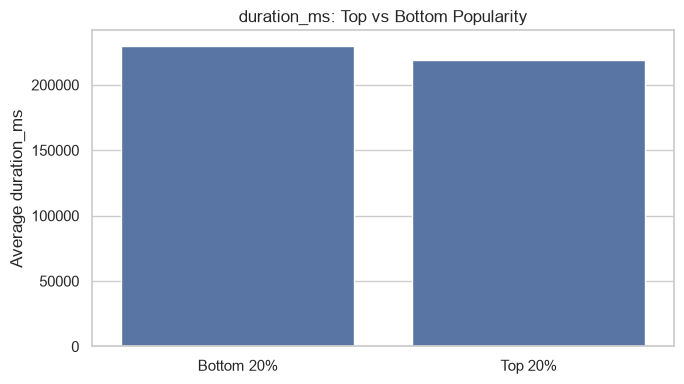

In [29]:
# plot differences between top and bottom groups for each feature
extreme_comparison_pd = extreme_comparison.toPandas()

for feature in comparison_features:
    plt.figure(figsize=(7, 4))

    sns.barplot(
        data=extreme_comparison_pd,
        x="popularity_group",
        y=feature,
        order=["Bottom 20%", "Top 20%"]
    )

    plt.title(f"{feature}: Top vs Bottom Popularity")
    plt.xlabel("")
    plt.ylabel(f"Average {feature}")
    plt.tight_layout()
    plt.show()

## Q8 - Are explicit songs different from non-explicit songs?

In [30]:
# comparasion of explicit vs non-explicit tracks
explicit_analysis = (
    track_df
    .filter(F.col("explicit").isNotNull())
    .groupBy("explicit")
    .agg(
        F.count("*").alias("track_count"),
        F.avg("popularity").alias("average_popularity"),
        F.avg("danceability").alias("average_danceability"),
        F.avg("energy").alias("average_energy"),
        F.avg("acousticness").alias("average_acousticness"),
        F.avg("speechiness").alias("average_speechiness"),
        F.avg("loudness").alias("average_loudness"),
        F.avg("duration_ms").alias("average_duration_ms")
    )
    .orderBy("explicit")
)

explicit_analysis.show(truncate=False)

+--------+-----------+------------------+--------------------+------------------+--------------------+-------------------+------------------+-------------------+
|explicit|track_count|average_popularity|average_danceability|average_energy    |average_acousticness|average_speechiness|average_loudness  |average_duration_ms|
+--------+-----------+------------------+--------------------+------------------+--------------------+-------------------+------------------+-------------------+
|false   |82036      |32.85391100074531 |0.5557166695109467  |0.6265401672022036|0.3377722091325769  |0.07604935759910282|-8.673482861182896|231407.04972207325 |
|true    |7704       |36.884198684665975|0.6308457943925234  |0.7187764927310489|0.2272601562811527  |0.20876037123572175|-6.640947559709249|205050.18639667705 |
+--------+-----------+------------------+--------------------+------------------+--------------------+-------------------+------------------+-------------------+



c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


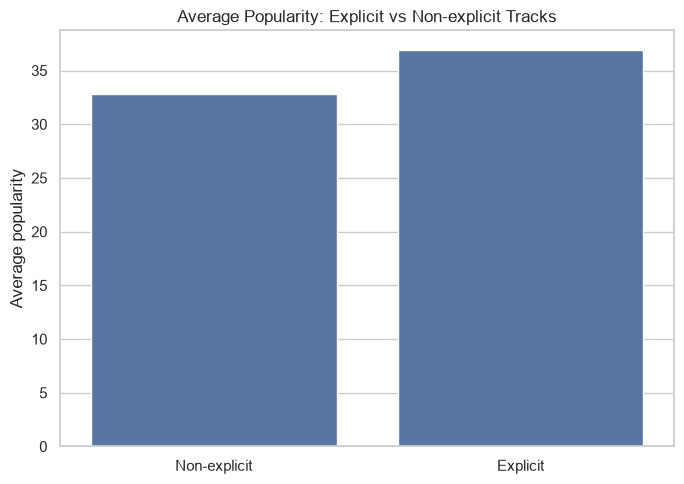

In [31]:
# plot av. popularity for explicit vs non-explicit tracks
explicit_pd = explicit_analysis.toPandas()

explicit_pd["explicit_label"] = explicit_pd["explicit"].map({
    True: "Explicit",
    False: "Non-explicit",
    1: "Explicit",
    0: "Non-explicit"
})

plt.figure(figsize=(7, 5))
sns.barplot(
    data=explicit_pd,
    x="explicit_label",
    y="average_popularity"
)
plt.title("Average Popularity: Explicit vs Non-explicit Tracks")
plt.xlabel("")
plt.ylabel("Average popularity")
plt.tight_layout()
plt.show()

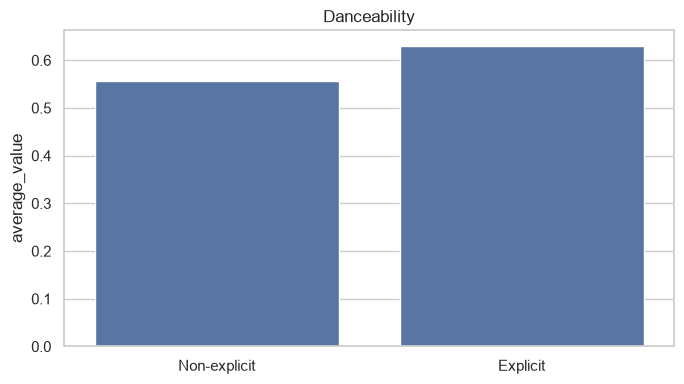

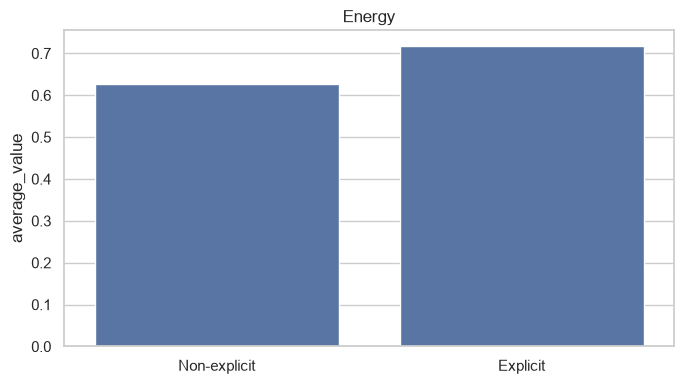

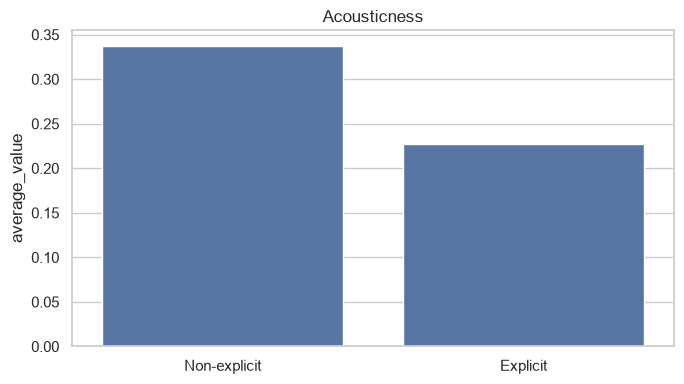

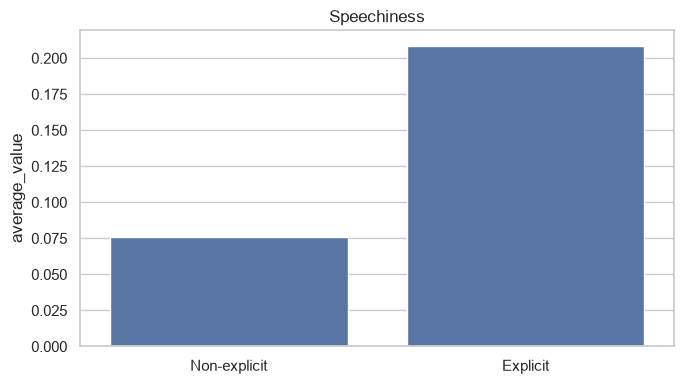

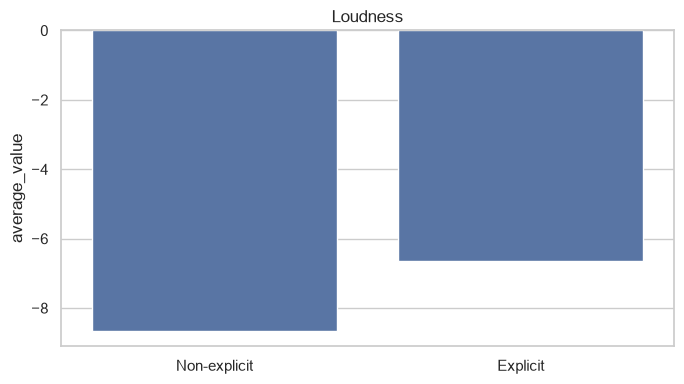

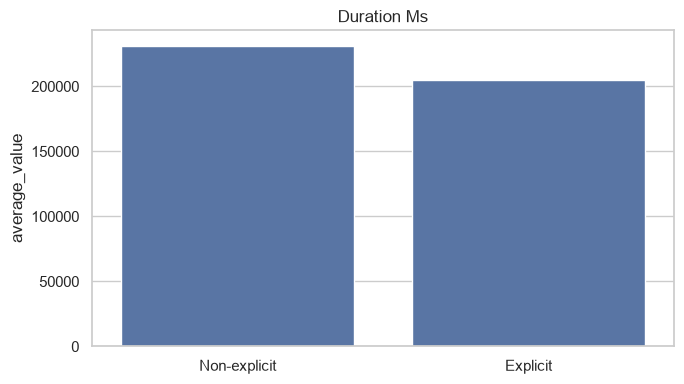

In [32]:
# comparation of audio features between explicit and non-explicit tracks
explicit_features_pd = explicit_pd.melt(
    id_vars=["explicit_label"],
    value_vars=[
        "average_danceability",
        "average_energy",
        "average_acousticness",
        "average_speechiness",
        "average_loudness",
        "average_duration_ms"
    ],
    var_name="feature",
    value_name="average_value"
)

for feature in explicit_features_pd["feature"].unique():
    plot_data = explicit_features_pd[
        explicit_features_pd["feature"] == feature
    ]

    plt.figure(figsize=(7, 4))
    sns.barplot(
        data=plot_data,
        x="explicit_label",
        y="average_value"
    )
    plt.title(feature.replace("average_", "").replace("_", " ").title())
    plt.xlabel("")
    plt.tight_layout()
    plt.show()

## Q9 - Which artists are the most popular?

In [33]:
# separate artists from the artists column and put them into individual rows
artists_df = (
    track_df
    .filter(
        F.col("artists").isNotNull() &
        (F.trim(F.col("artists")) != "")
    )
    .withColumn(
        "artists_clean",
        F.regexp_replace(
            F.regexp_replace(F.col("artists"), r"[\[\]]", ""),
            r"""['"]""",
            ""
        )
    )
    .withColumn(
        "artist",
        F.explode(F.split(F.col("artists_clean"), ","))
    )
    .withColumn("artist", F.trim(F.col("artist")))
    .filter(F.col("artist") != "")
)

artists_df.select("artist", "track_name", "popularity").show(
    10, truncate=False
)

+----------------------------------------------+---------------------------------------------+----------+
|artist                                        |track_name                                   |popularity|
+----------------------------------------------+---------------------------------------------+----------+
|Paul Kalkbrenner;Pig&Dan                      |Böxig Leise - Pig & Dan Remix                |22.0      |
|Chad Daniels                                  |Thanksgiving Chicken                         |24.0      |
|Old Crow Medicine Show                        |Poor Man                                     |30.0      |
|Pigface                                       |Hips, Tits, Lips, Power!                     |20.0      |
|Calcinha Preta;Gusttavo Lima                  |Agora Estou Sofrendo - Ao Vivo               |47.0      |
|İlhan İrem                                    |Yemyeşil Bir Deniz                           |44.0      |
|Red Hot Chili Peppers                        

In [38]:
# Rank artists by average popularity, considering only those with at least 10 tracks
artist_popularity = (
    artists_df
    .groupBy("artist")
    .agg(
        F.avg("popularity").alias("average_popularity"),
        F.countDistinct("track_id").alias("track_count")
    )
    .filter(F.col("track_count") >= 10)
    .orderBy(F.desc("average_popularity"))
)

# Convert to Pandas DataFrame
artist_popularity_pd = artist_popularity.toPandas()

# Display the top 10 artists
display(artist_popularity_pd.head(10))

c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,artist,average_popularity,track_count
0,Bad Bunny,85.272727,22
1,Travis Scott,74.933333,15
2,Frank Ocean,74.705882,17
3,The Neighbourhood,73.920000,25
4,Radiohead,73.545455,11
5,Stray Kids,73.090909,22
6,System Of A Down,72.750000,12
7,TWICE,72.470588,17
8,SEVENTEEN,71.428571,14
9,Halsey,70.625000,16


c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


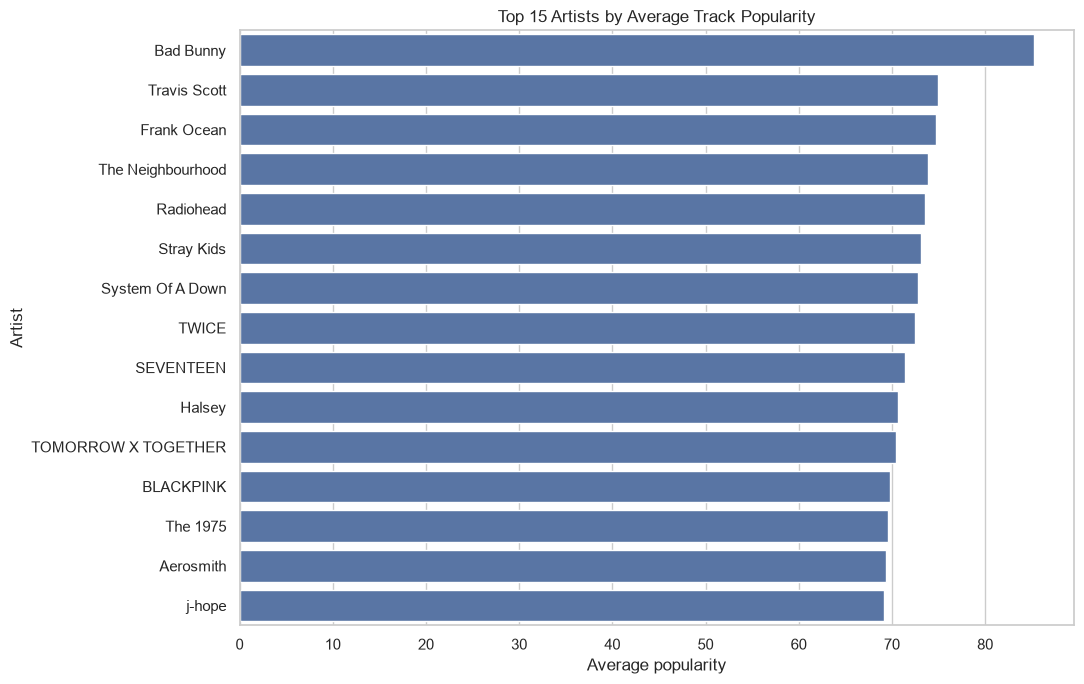

In [35]:
# top 15 artists by av popularity
artist_popularity_pd = artist_popularity.limit(15).toPandas()

plt.figure(figsize=(11, 7))
sns.barplot(
    data=artist_popularity_pd,
    x="average_popularity",
    y="artist"
)
plt.title("Top 15 Artists by Average Track Popularity")
plt.xlabel("Average popularity")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

## Q10 - Which tracks are the most popular?

In [36]:
# top 20 tracks by popularity, with ties included
top_tracks = (
    track_df
    .select(
        "track_id",
        "track_name",
        "artists",
        "album_name",
        "popularity",
        "track_id"
    )
    .orderBy(
        F.desc("popularity"),
        F.asc("track_name")
    )
)

top_tracks.show(20, truncate=False)

+----------------------+-------------------------------------+--------------------------+-------------------------------------------------------------------+----------+----------------------+
|track_id              |track_name                           |artists                   |album_name                                                         |popularity|track_id              |
+----------------------+-------------------------------------+--------------------------+-------------------------------------------------------------------+----------+----------------------+
|3nqQXoyQOWXiESFLlDF1hG|Unholy (feat. Kim Petras)            |Sam Smith;Kim Petras      |Unholy (feat. Kim Petras)                                          |100.0     |3nqQXoyQOWXiESFLlDF1hG|
|2tTmW7RDtMQtBk7m2rYeSw|Quevedo: Bzrp Music Sessions, Vol. 52|Bizarrap;Quevedo          |Quevedo: Bzrp Music Sessions, Vol. 52                              |99.0      |2tTmW7RDtMQtBk7m2rYeSw|
|4uUG5RXrOk84mYEfFvj3cK|I'm Good (Blue) 

In [ ]:

# convert to pandas again
top_tracks_pd = top_tracks.limit(15).toPandas()

# inspect columns to see if there are any duplicates
print("Original columns:", top_tracks_pd.columns.tolist())

# remive duplicates keeping only first occurrence
top_tracks_pd = top_tracks_pd.loc[
    :, ~top_tracks_pd.columns.duplicated()
].copy()

print("Columns after removing duplicates:", top_tracks_pd.columns.tolist())

# chose the columns for the table 
top_tracks_table = top_tracks_pd[
    ["track_name", "artists", "popularity", "track_id"]
].copy()

top_tracks_table = top_tracks_table.rename(columns={
    "track_name": "Track",
    "artists": "Artist",
    "popularity": "Popularity",
    "track_id": "Track ID"
})

# rank, adding a +1 bc array starts in 0
top_tracks_table.insert(0, "Rank", range(1, len(top_tracks_table) + 1))

display(top_tracks_table.style.hide(axis="index"))


c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Original columns: ['track_id', 'track_name', 'artists', 'album_name', 'popularity', 'track_id']
Columns after removing duplicates: ['track_id', 'track_name', 'artists', 'album_name', 'popularity']


Rank,Track,Artist,Popularity,Track ID
1,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100.000000,3nqQXoyQOWXiESFLlDF1hG
2,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,99.000000,2tTmW7RDtMQtBk7m2rYeSw
3,I'm Good (Blue),David Guetta;Bebe Rexha,98.000000,4uUG5RXrOk84mYEfFvj3cK
4,La Bachata,Manuel Turizo,98.000000,5ww2BF9slyYgNOk37BlC4u
5,Me Porto Bonito,Bad Bunny;Chencho Corleone,97.000000,6Sq7ltF9Qa7SNFBsV5Cogx
6,Tití Me Preguntó,Bad Bunny,97.000000,1IHWl5LamUGEuP4ozKQSXZ
7,I Ain't Worried,OneRepublic,96.000000,4h9wh7iOZ0GGn8QVp4RAOB
8,Under The Influence,Chris Brown,96.000000,5IgjP7X4th6nMNDh4akUHb
9,Efecto,Bad Bunny,95.500000,5Eax0qFko2dh7Rl2lYs3bx
10,As It Was,Harry Styles,95.000000,4LRPiXqCikLlN15c3yImP7


c:\Users\albac\OneDrive\Proyectos\spotify-analytics-hit-prediction\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


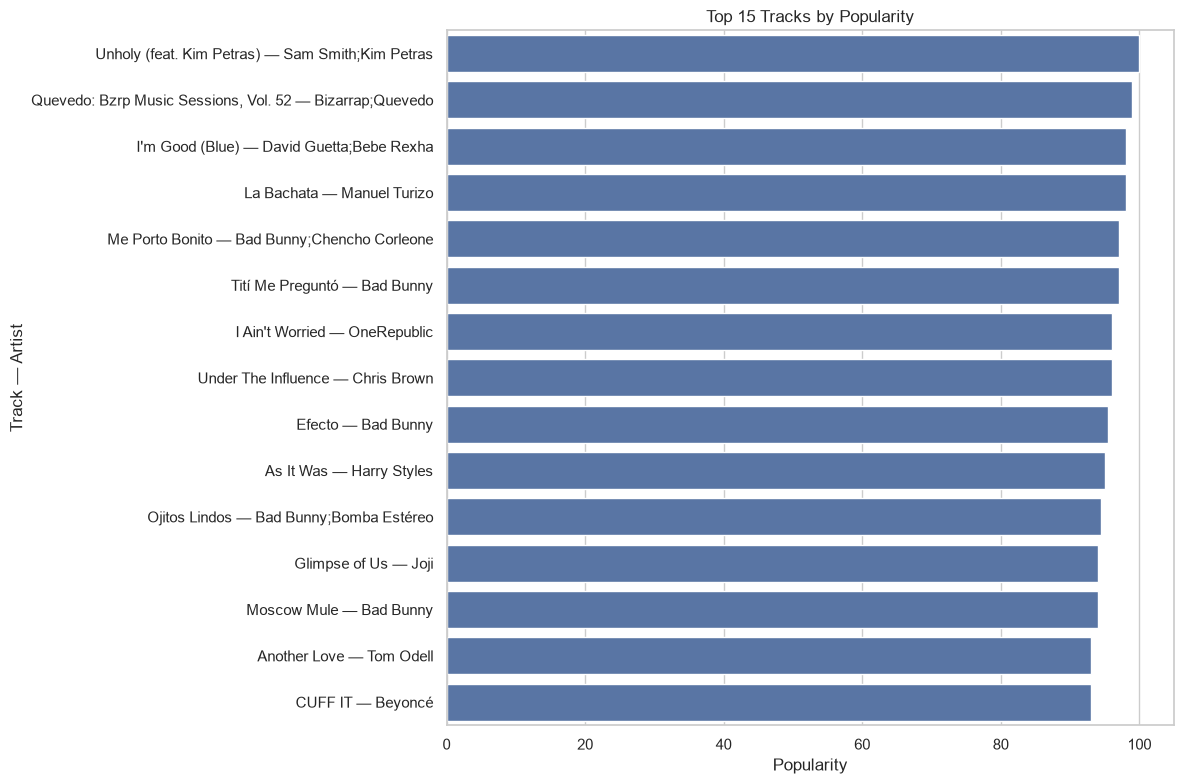

In [ ]:
# top 15 tracks by popularity
top_tracks_pd = top_tracks.limit(15).toPandas()

top_tracks_pd["track_label"] = (
    top_tracks_pd["track_name"].fillna("Unknown track")
    + " — "
    + top_tracks_pd["artists"].fillna("Unknown artist")
)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_tracks_pd,
    x="popularity",
    y="track_label"
)
plt.title("Top 15 Tracks by Popularity")
plt.xlabel("Popularity")
plt.ylabel("Track — Artist")
plt.tight_layout()
plt.show()